# Pac-Man com fases e fantasmas que mudam

Mesmo Q-learning do outro notebook, mas em **rodadas**. A cada rodada o Pac-Man treina até conseguir chegar na cereja **E**. Quando consegue, a **fase** troca para o próximo labirinto fixo (`PHASES`, cicla) e os fantasmas **T** são sorteados de novo. A Q-table é mantida, mas esquecemos o que ele sabia das células que mudaram.

In [46]:
import numpy as np
import random
from collections import deque
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle, Wedge
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 80


## 1. Labirinto e ambiente
- `BASE_MAZE` — labirinto original (fase 1): `S` início, `E` cereja, `#` parede, `T` fantasma, `.` caminho com bolinha.
- `maze` — cópia mutável do labirinto atual: a fase e os fantasmas mudam entre rodadas.
- `PHASES` — fases fixas, só com paredes (`S` e `E` nos cantos). Os fantasmas são sorteados a cada rodada. A fase 1 é o labirinto original sem os `T`.
- `phase` — índice da fase atual em `PHASES`.
- `PELLET_BONUS = 0` — sem bônus, a bolinha não guia mais o walker (antes era 3), o que deixa o aprendizado mais difícil.
- `step` — devolve (novo estado, recompensa, terminou?): passo normal `-1`, parede `-5`, fantasma `-100` (fim), cereja `+100` (fim).

In [47]:
BASE_MAZE = [
    "S..#....#...T...",
    ".#.#.T#.#.#.###.",
    ".#...#..#.#...#.",
    ".T##.#.##.###.#.",
    "...#.#.T..#...#.",
    "#T.#T#.####.###.",
    "...T...#....#...",
    ".#T..#.#.##.#.#.",
    ".#.###.#.#T.#.#.",
    ".#.....#.#..#.#.",
    ".####T.#.####.#.",
    ".....T..........",
    ".######.######T.",
    ".#...T..#.....#.",
    ".#.#####.#.##.#.",
    "...T....T#...#.E",
]
maze = [list(row) for row in BASE_MAZE]
N_ROWS, N_COLS = len(maze), len(maze[0])
N_GHOSTS = sum(row.count("T") for row in maze)

PHASES = [
    [row.replace("T", ".") for row in BASE_MAZE],
    [
        "S#..#.##.##.....",
        "...#..#.#.#..#..",
        ".........####...",
        ".#..#....#......",
        ".#..##.#...#....",
        "...##....#.....#",
        "#...###..#.##...",
        "..#...##...#.#..",
        "........#.##....",
        ".##.#....#...#..",
        "..........#.....",
        "#.....#...#.....",
        ".#..##..#.#..##.",
        "................",
        ".........#...##.",
        "..#.#..##...###E",
    ],
    [
        "S..##.#.....#...",
        "...##.....#..##.",
        "....##.#....#.#.",
        "#...##.#........",
        ".#.#..#...#.....",
        "#.....#..#..#..#",
        "........##......",
        ".###..#...####.#",
        ".........#......",
        "#...#.....#.....",
        "#.....#..###....",
        "..#.#....#....#.",
        "..#..#.###......",
        "...##.#..#.#...#",
        ".#..............",
        ".......#.......E",
    ],
    [
        "S...#..#..##....",
        "..#...#.#..##..#",
        ".....##......#..",
        ".#...#..#.#.##..",
        "...#...##..###..",
        "....#...#.#....#",
        "..#.#..##.#..#..",
        "...#...........#",
        ".#.#....#.#..#..",
        "..###...#.#....#",
        "#.#...#.#.###...",
        "#..#.#...#..##.#",
        "...##...##.#....",
        "..#..#..........",
        "#.#.###......#.#",
        "..####...#.#...E",
    ],
]
phase = 0
ACTIONS = {0: (-1, 0), 1: (1, 0), 2: (0, -1), 3: (0, 1)}
ACTION_NAME = {0: "↑", 1: "↓", 2: "←", 3: "→"}
PELLET_BONUS = 0


def find(char):
    return next((i, row.index(char)) for i, row in enumerate(maze) if char in row)


START, EXIT = find("S"), find("E")


def step(state, action, eaten):
    di, dj = ACTIONS[action]
    i, j = state[0] + di, state[1] + dj
    if not (0 <= i < N_ROWS and 0 <= j < N_COLS) or maze[i][j] == "#":
        return state, -5, False
    cell = maze[i][j]
    if cell == "T":
        return (i, j), -100, True
    if cell == "E":
        return (i, j), +100, True
    if cell == "." and (i, j) not in eaten:
        eaten.add((i, j))
        return (i, j), -1 + PELLET_BONUS, False
    return (i, j), -1, False

## 2. Trocar de fase e mudar os fantasmas
- `solvable` — busca em largura: existe caminho livre de `S` até `E`, sem passar por parede ou fantasma?
- `place_ghosts` — sorteia `N_GHOSTS` fantasmas em células livres, repetindo até existir caminho de `S` até `E`.
- `next_phase` — troca para a próxima fase fixa (cicla), sorteia fantasmas novos e devolve as células que mudaram.

In [48]:
def solvable():
    visited, queue = {START}, deque([START])
    while queue:
        i, j = queue.popleft()
        if (i, j) == EXIT:
            return True
        for di, dj in ACTIONS.values():
            nxt = (i + di, j + dj)
            if 0 <= nxt[0] < N_ROWS and 0 <= nxt[1] < N_COLS and nxt not in visited and maze[nxt[0]][nxt[1]] not in "#T":
                visited.add(nxt)
                queue.append(nxt)
    return False


def place_ghosts(rng):
    free = [(i, j) for i in range(N_ROWS) for j in range(N_COLS) if maze[i][j] == "."]
    while True:
        chosen = rng.sample(free, N_GHOSTS)
        for i, j in chosen:
            maze[i][j] = "T"
        if solvable():
            return
        for i, j in chosen:
            maze[i][j] = "."


def next_phase(rng):
    global phase
    previous = [row[:] for row in maze]
    phase = (phase + 1) % len(PHASES)
    for i, row in enumerate(PHASES[phase]):
        maze[i][:] = row
    place_ghosts(rng)
    return [(i, j) for i in range(N_ROWS) for j in range(N_COLS) if previous[i][j] != maze[i][j]]

## 3. Treino por rodadas
Parâmetros:
- `alpha` — taxa de aprendizado (0.1, mais lento que o padrão 0.2, para dificultar).
- `gamma` — peso do futuro.
- `EPS_FIRST` / `EPS_NEXT` — exploração inicial na 1ª rodada e nas seguintes (menor, porque ele já sabe algo); `EPS_MIN` e `DECAY` controlam a queda.
- `MAX_STEPS` — limite de passos por episódio; `MAX_EP` — limite de episódios por rodada.
- `CHECK` — de quantos em quantos episódios testamos o walker sem exploração; se ele sai vivo, a rodada pode acabar.
- `MIN_COVERAGE = 0.9` — a rodada só termina depois que o walker pisou em pelo menos 90% das células alcançáveis da fase.

Funções:
- `run_greedy` — walker sem exploração; devolve (caminho, saiu vivo?).
- `reachable` — células livres alcançáveis a partir de `S`, sem atravessar parede ou fantasma.
- `explore` — exploração dirigida: vai para o vizinho menos visitado (empate sorteado) em vez de andar ao acaso, e evita o que já sabe que mata (Q < -50). Assim o walker varre a fase inteira em vez de girar no mesmo lugar.
- `coverage_ratio` — fração das células alcançáveis que já foram visitadas na rodada.
- `train_round` — treina até o walker sair vivo e cobrir `MIN_COVERAGE`. Devolve (episódios, caminho final, snapshots); cada snapshot guarda (episódio, caminho, resultado) do episódio 1 e de cada `CHECK`-ésimo, para a animação. Enquanto a cobertura não é atingida, o epsilon não cai abaixo de 0.3 (senão a exploração zera antes de varrer tudo).

Laço principal:
- `visits` — quantas vezes o walker pisou em cada célula na rodada atual.
- `rounds` — lista de (rodada, labirinto, caminho, episódios para passar).
- `q_tables` e `visits_by_round` — Q-table e visitas ao fim de cada rodada, para mostrar o que ele aprendeu.
- `phase_of_round` — número da fase de cada rodada.
- `shown_episodes` — episódios de treino mostrados na animação: o início do aprendizado (ep. 1) e um do meio; o último clipe é o teste final da rodada.
- Ao trocar de fase, zeramos a Q das ações que levam a células que mudaram, para ele esquecer o que sabia delas.

In [49]:
alpha, gamma = 0.1, 0.5
EPS_FIRST, EPS_NEXT, EPS_MIN, DECAY = 1.0, 0.4, 0.01, 0.998
MAX_STEPS, MAX_EP, CHECK = 400, 5000, 20
N_ROUNDS, SEED = 6, 42
MIN_COVERAGE = 0.9


def run_greedy(Q):
    state, path, eaten = START, [START], set()
    for _ in range(MAX_STEPS):
        state, _, done = step(state, int(np.argmax(Q[state])), eaten)
        path.append(state)
        if done:
            return path, state == EXIT
    return path, False


def reachable():
    visited, queue = {START}, deque([START])
    while queue:
        i, j = queue.popleft()
        for di, dj in ACTIONS.values():
            nxt = (i + di, j + dj)
            if 0 <= nxt[0] < N_ROWS and 0 <= nxt[1] < N_COLS and nxt not in visited and maze[nxt[0]][nxt[1]] not in "#T":
                visited.add(nxt)
                queue.append(nxt)
    return visited


def explore(Q, state):
    options = [(visits[state[0] + di, state[1] + dj], random.random(), action) for action, (di, dj) in ACTIONS.items()
               if 0 <= state[0] + di < N_ROWS and 0 <= state[1] + dj < N_COLS and maze[state[0] + di][state[1] + dj] != "#"
               and Q[state][action] > -50]
    return min(options)[2] if options else random.randint(0, 3)


def coverage_ratio():
    cells = reachable()
    return sum(visits[cell] > 0 for cell in cells) / len(cells)


def train_round(Q, eps):
    snapshots = []
    visits[:] = 0
    for episode in range(1, MAX_EP + 1):
        state, eaten, trail = START, set(), [START]
        for _ in range(MAX_STEPS):
            action = explore(Q, state) if random.random() < eps else int(np.argmax(Q[state]))
            new_state, reward, done = step(state, action, eaten)
            target = reward if done else reward + gamma * np.max(Q[new_state])
            Q[state][action] += alpha * (target - Q[state][action])
            state = new_state
            visits[state] += 1
            trail.append(state)
            if done:
                break
        if episode == 1 or episode % CHECK == 0:
            outcome = "exit" if state == EXIT else "died" if maze[state[0]][state[1]] == "T" else "lost"
            snapshots.append((episode, trail, outcome))
        eps = max(EPS_MIN if coverage_ratio() >= MIN_COVERAGE else 0.3, eps * DECAY)
        if episode % CHECK == 0:
            path, reached_exit = run_greedy(Q)
            if reached_exit and coverage_ratio() >= MIN_COVERAGE:
                return episode, path, snapshots
    return None, run_greedy(Q)[0], snapshots


random.seed(SEED)
np.random.seed(SEED)
rng = random.Random(SEED)
visits = np.zeros((N_ROWS, N_COLS))
Q = np.zeros((N_ROWS, N_COLS, 4))
rounds = []
q_tables, visits_by_round = {}, {}
phase_of_round = {1: 1}
shown_episodes = {}

for round_no in range(1, N_ROUNDS + 1):
    episodes_needed, path, snapshots = train_round(Q, EPS_FIRST if round_no == 1 else EPS_NEXT)
    rounds.append((round_no, [row[:] for row in maze], path, episodes_needed))
    q_tables[round_no], visits_by_round[round_no] = Q.copy(), visits.copy()
    picks = snapshots[:1] + (snapshots[len(snapshots) // 2:][:1] if len(snapshots) > 2 else [])
    shown_episodes[round_no] = [(ep, [row[:] for row in maze], trail, outcome) for ep, trail, outcome in picks]
    if episodes_needed is None:
        print(f"Rodada {round_no}: não passou em {MAX_EP} episódios. Parando.")
        break
    print(f"Rodada {round_no}: passou após {episodes_needed} episódios ({len(path) - 1} passos, {coverage_ratio():.0%} da fase percorrida)")
    if round_no < N_ROUNDS:
        for changed_i, changed_j in next_phase(rng):
            for action, (di, dj) in ACTIONS.items():
                if 0 <= changed_i - di < N_ROWS and 0 <= changed_j - dj < N_COLS:
                    Q[changed_i - di, changed_j - dj, action] = 0
        phase_of_round[round_no + 1] = phase + 1
        print(f"   -> fase {phase + 1} e fantasmas novos")

Rodada 1: passou após 540 episódios (36 passos, 99% da fase percorrida)
   -> fase 2 e fantasmas novos
Rodada 2: passou após 740 episódios (30 passos, 90% da fase percorrida)
   -> fase 3 e fantasmas novos
Rodada 3: passou após 600 episódios (38 passos, 96% da fase percorrida)
   -> fase 4 e fantasmas novos
Rodada 4: passou após 520 episódios (30 passos, 100% da fase percorrida)
   -> fase 1 e fantasmas novos
Rodada 5: passou após 340 episódios (30 passos, 99% da fase percorrida)
   -> fase 2 e fantasmas novos
Rodada 6: passou após 760 episódios (30 passos, 100% da fase percorrida)


## 4. Onde e qual caminho ele aprendeu
Por rodada: o caminho do teste final (ciano), as células que ele explorou (amarelo) e a melhor ação aprendida em cada uma (setas).

`ARROW` dá o deslocamento (dx, dy) de cada ação no gráfico, onde o eixo y cresce para baixo.

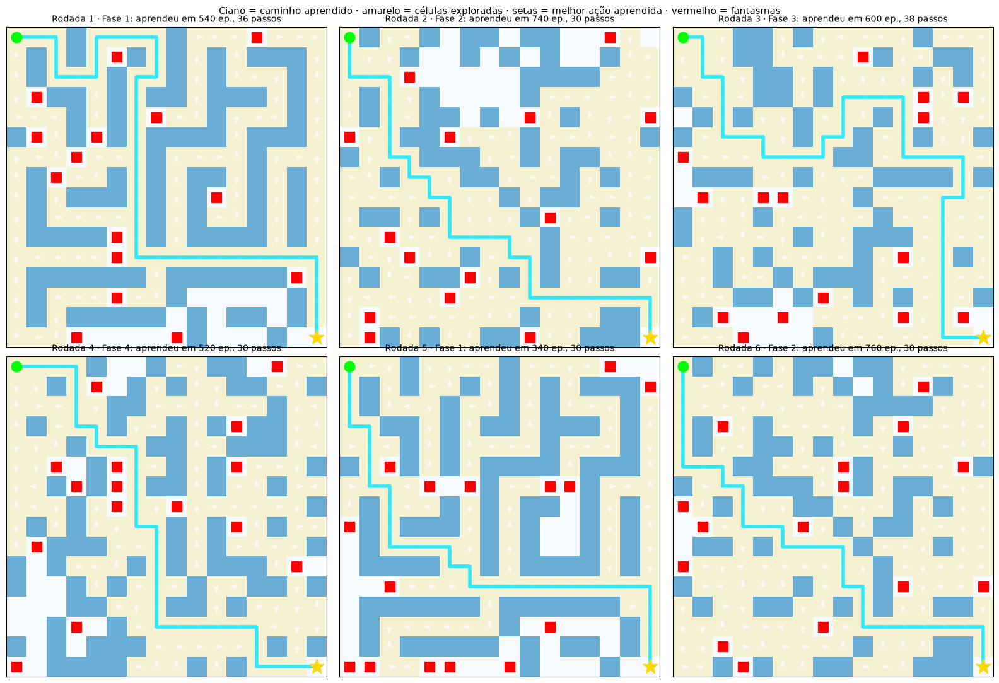

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(16, 11))
ARROW = {0: (0, -1), 1: (0, 1), 2: (-1, 0), 3: (1, 0)}
for ax, (round_no, round_maze, path, episodes_needed) in zip(axes.flat, rounds):
    ax.set_facecolor("black")
    ax.imshow([[1 if cell == "#" else 0 for cell in row] for row in round_maze], cmap="Blues", vmin=0, vmax=2)
    for i in range(N_ROWS):
        for j in range(N_COLS):
            if visits_by_round[round_no][i, j] > 0 and round_maze[i][j] in ".S":
                ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color="#f1c40f", alpha=.18, lw=0))
                dx, dy = ARROW[int(np.argmax(q_tables[round_no][i, j]))]
                ax.arrow(j, i, dx * .3, dy * .3, head_width=.18, color="white", alpha=.7, length_includes_head=True)
            if round_maze[i][j] == "T":
                ax.plot(j, i, "s", color="red", ms=11)
    ys, xs = zip(*path)
    ax.plot(xs, ys, "-", color="#00e5ff", lw=4, alpha=.8)
    ax.plot(*START[::-1], "o", color="lime", ms=12)
    ax.plot(*EXIT[::-1], "*", color="gold", ms=18)
    ax.set_title(f"Rodada {round_no} · Fase {phase_of_round[round_no]}: " + (f"aprendeu em {episodes_needed} ep., {len(path) - 1} passos" if episodes_needed else "NÃO passou"), fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Ciano = caminho aprendido · amarelo = células exploradas · setas = melhor ação aprendida · vermelho = fantasmas", fontsize=11)
plt.tight_layout()
plt.show()

## 5. Animação
- `make_video` monta uma lista de *clipes* `(título, labirinto, caminho, resultado)`: para cada rodada, os episódios de treino em `shown_episodes` e depois o teste final com a rota aprendida em ciano. Episódios longos mostram só os primeiros `max_steps` passos (resultado `"cut"`, sem banner).
- Há um mapa de paredes por clipe, e só o do clipe atual fica visível. A bolinha existe em toda célula que é `.` em alguma rodada (onde havia fantasma, volta a ter bolinha).
- A função só devolve a animação, sem salvar arquivo; o player com play/pausa aparece no notebook.

In [51]:
GHOST_COLORS = ["#ff0000", "#ffb8ff", "#00ffff", "#ffb852"]


def draw_ghost(ax, x, y, color):
    parts = [ax.add_patch(Circle((x, y - .05), .33, fc=color, ec="none", zorder=3)),
             ax.add_patch(Rectangle((x - .33, y - .05), .66, .36, fc=color, ec="none", zorder=3))]
    for dx in (-.12, .12):
        parts.append(ax.add_patch(Circle((x + dx, y - .1), .09, fc="white", ec="none", zorder=4)))
        parts.append(ax.add_patch(Circle((x + dx + .03, y - .1), .04, fc="#1a1aa6", ec="none", zorder=4)))
    return parts


def make_video(rounds, max_steps=100, pause=4, fps=6):
    clips = []
    for round_no, round_maze, path, episodes_needed in rounds:
        for ep, ep_maze, trail, outcome in shown_episodes[round_no]:
            if len(trail) > max_steps:
                outcome = "cut"
            clips.append((f"Rodada {round_no} · Fase {phase_of_round[round_no]}: treinando, episódio {ep}", ep_maze, trail, outcome))
        title_text = f"Rodada {round_no} · Fase {phase_of_round[round_no]}" + (f" · caminho aprendido (em {episodes_needed} ep.)" if episodes_needed else "")
        clips.append((title_text, round_maze, path, "exit" if episodes_needed else "lost"))
    frame_list = []
    for k, (_, _, path, _) in enumerate(clips):
        shown = min(len(path), max_steps)
        frame_list += [(k, p) for p in range(shown)] + [(k, shown - 1)] * pause

    fig, ax = plt.subplots(figsize=(6.5, 7))
    ax.set_facecolor("black")
    cmap = ListedColormap(["#000000", "#1a1aa6"])
    wall_images = [ax.imshow([[1 if cell == "#" else 0 for cell in row] for row in clip_maze], cmap=cmap, vmin=0, vmax=1)
                   for _, clip_maze, _, _ in clips]

    pellets = {(i, j): ax.add_patch(Circle((j, i), .09, fc="#ffd9a0", ec="none", zorder=2))
               for i in range(N_ROWS) for j in range(N_COLS)
               if any(clip_maze[i][j] == "." for _, clip_maze, _, _ in clips)}
    ghost_artists = [[draw_ghost(ax, j, i, GHOST_COLORS[g % 4])
                      for g, (i, j) in enumerate((i, j) for i in range(N_ROWS) for j in range(N_COLS) if clip_maze[i][j] == "T")]
                     for _, clip_maze, _, _ in clips]
    exit_i, exit_j = EXIT
    for dx in (-.15, .15):
        ax.add_patch(Circle((exit_j + dx, exit_i + .15), .15, fc="#e60000", ec="none", zorder=3))
    ax.plot([exit_j - .15, exit_j, exit_j + .15], [exit_i, exit_i - .3, exit_i], color="#2ecc71", lw=2, zorder=3)
    ax.set_xticks([])
    ax.set_yticks([])

    learned_line, = ax.plot([], [], "-", color="#00e5ff", lw=4, alpha=.55, zorder=4)
    trail_line, = ax.plot([], [], "-", color="#f39c12", lw=2, alpha=.6)
    walker = Wedge((0, 0), .4, 30, 330, fc="#f1c40f", ec="black", lw=1.5, zorder=5)
    ax.add_patch(walker)
    title = ax.set_title("", fontsize=10)
    banner = ax.text(N_COLS / 2 - .5, N_ROWS / 2 - .5, "", ha="center", va="center", fontsize=34, weight="bold")
    angle = [0]

    def update(frame):
        k, p = frame_list[frame]
        name, clip_maze, path, result = clips[k]
        ys, xs = zip(*path[:p + 1])
        trail_line.set_data(xs, ys)
        learned_ys, learned_xs = zip(*path) if "aprendido" in name else ((), ())
        learned_line.set_data(learned_xs, learned_ys)
        visited = set(path[:p + 1])
        for (i, j), pellet in pellets.items():
            pellet.set_visible(clip_maze[i][j] == "." and (i, j) not in visited)
        for index, image in enumerate(wall_images):
            image.set_visible(index == k)
        for index, parts in enumerate(ghost_artists):
            for ghost in parts:
                for artist in ghost:
                    artist.set_visible(index == k)
        if p > 0 and (xs[-1], ys[-1]) != (xs[-2], ys[-2]):
            angle[0] = np.degrees(np.arctan2(ys[-1] - ys[-2], xs[-1] - xs[-2]))
        mouth = 35 if p % 2 == 0 else 5
        walker.set_center((xs[-1], ys[-1]))
        walker.set_theta1(angle[0] + mouth)
        walker.set_theta2(angle[0] + 360 - mouth)
        title.set_text(f"{name}\npasso {p}")
        if p == min(len(path), max_steps) - 1:
            text, color = {"exit": ("SAIU VIVO!", "#27ae60"), "died": ("MORREU!", "#c0392b"), "cut": ("", "black")}.get(result, ("PERDIDO", "#7f8c8d"))
            banner.set_text(text)
            banner.set_color(color)
        else:
            banner.set_text("")
        return trail_line, walker, title, banner

    anim = animation.FuncAnimation(fig, update, frames=len(frame_list), interval=1000 / fps, blit=False)
    plt.close(fig)
    return anim


anim = make_video(rounds)
HTML(anim.to_jshtml())